<a href="https://colab.research.google.com/github/Arnab9144/song-206/blob/main/song_206.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Import the libraries**

In [71]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import LabelEncoder

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

import warnings
warnings.filterwarnings('ignore')

**Dataset Upload**

In [72]:
from google.colab import files
uploaded = files.upload()

Saving songs_normalize.csv to songs_normalize (2).csv


**Upload the dataset and print first 5 rows**

In [73]:
df = pd.read_csv("songs_normalize.csv")
df.head()

,artist,song,duration_ms,explicit,year,popularity,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,genre
0,Britney Spears,Oops!...I Did It Again,211160,False,2000,77,0.751,0.834,1,-5.444,0,0.0437,0.3000,0.000018,0.3550,0.894,95.053,pop
1,blink-182,All The Small Things,167066,False,1999,79,0.434,0.897,0,-4.918,1,0.0488,0.0103,0.000000,0.6120,0.684,148.726,"rock, pop"
2,Faith Hill,Breathe,250546,False,1999,66,0.529,0.496,7,-9.007,1,0.0290,0.1730,0.000000,0.2510,0.278,136.859,"pop, country"
3,Bon Jovi,It's My Life,224493,False,2000,78,0.551,0.913,0,-4.063,0,0.0466,0.0263,0.000013,0.3470,0.544,119.992,"rock, metal"
4,*NSYNC,Bye Bye Bye,200560,False,2000,65,0.614,0.928,8,-4.806,0,0.0516,0.0408,0.001040,0.0845,0.879,172.656,pop


**Print first 5 rows**

In [74]:
print("First first five rows: ")
print(df.head())

First first five rows: 
           artist                    song  duration_ms  explicit  year  \
0  Britney Spears  Oops!...I Did It Again       211160     False  2000   
1       blink-182    All The Small Things       167066     False  1999   
2      Faith Hill                 Breathe       250546     False  1999   
3        Bon Jovi            It's My Life       224493     False  2000   
4          *NSYNC             Bye Bye Bye       200560     False  2000   

   popularity  danceability  energy  key  loudness  mode  speechiness  \
0          77         0.751   0.834    1    -5.444     0       0.0437   
1          79         0.434   0.897    0    -4.918     1       0.0488   
2          66         0.529   0.496    7    -9.007     1       0.0290   
3          78         0.551   0.913    0    -4.063     0       0.0466   
4          65         0.614   0.928    8    -4.806     0       0.0516   

   acousticness  instrumentalness  liveness  valence    tempo         genre  
0        0.300

**Print last five rows**

In [75]:
print("First last rows: ")
print(df.tail())

First last rows: 
              artist                                    song  duration_ms  \
1995  Jonas Brothers                                  Sucker       181026   
1996    Taylor Swift                            Cruel Summer       178426   
1997    Blanco Brown                              The Git Up       200593   
1998       Sam Smith  Dancing With A Stranger (with Normani)       171029   
1999     Post Malone                                 Circles       215280   

      explicit  year  popularity  danceability  energy  key  loudness  mode  \
1995     False  2019          79         0.842   0.734    1    -5.065     0   
1996     False  2019          78         0.552   0.702    9    -5.707     1   
1997     False  2019          69         0.847   0.678    9    -8.635     1   
1998     False  2019          75         0.741   0.520    8    -7.513     1   
1999     False  2019          85         0.695   0.762    0    -3.497     1   

      speechiness  acousticness  instrumenta

**Dataset Size**

In [76]:
print("Rows : ", df.shape[0])
print("Columns :", df.shape[1])

Rows :  2000
Columns : 18


**Columns name**

In [77]:
print(df.columns.tolist())

['artist', 'song', 'duration_ms', 'explicit', 'year', 'popularity', 'danceability', 'energy', 'key', 'loudness', 'mode', 'speechiness', 'acousticness', 'instrumentalness', 'liveness', 'valence', 'tempo', 'genre']


**Dataset Information**

In [78]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 18 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   artist            2000 non-null   object 
 1   song              2000 non-null   object 
 2   duration_ms       2000 non-null   int64  
 3   explicit          2000 non-null   bool   
 4   year              2000 non-null   int64  
 5   popularity        2000 non-null   int64  
 6   danceability      2000 non-null   float64
 7   energy            2000 non-null   float64
 8   key               2000 non-null   int64  
 9   loudness          2000 non-null   float64
 10  mode              2000 non-null   int64  
 11  speechiness       2000 non-null   float64
 12  acousticness      2000 non-null   float64
 13  instrumentalness  2000 non-null   float64
 14  liveness          2000 non-null   float64
 15  valence           2000 non-null   float64
 16  tempo             2000 non-null   float64


**Statistical Summary**

In [79]:
df.describe()

,duration_ms,year,popularity,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo
count,2000.000000,2000.00000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000
mean,228748.124500,2009.49400,59.872500,0.667438,0.720366,5.378000,-5.512434,0.553500,0.103568,0.128955,0.015226,0.181216,0.551690,120.122558
std,39136.569008,5.85996,21.335577,0.140416,0.152745,3.615059,1.933482,0.497254,0.096159,0.173346,0.087771,0.140669,0.220864,26.967112
min,113000.000000,1998.00000,0.000000,0.129000,0.054900,0.000000,-20.514000,0.000000,0.023200,0.000019,0.000000,0.021500,0.038100,60.019000
25%,203580.000000,2004.00000,56.000000,0.581000,0.622000,2.000000,-6.490250,0.000000,0.039600,0.014000,0.000000,0.088100,0.386750,98.985750
50%,223279.500000,2010.00000,65.500000,0.676000,0.736000,6.000000,-5.285000,1.000000,0.059850,0.055700,0.000000,0.124000,0.557500,120.021500
75%,248133.000000,2015.00000,73.000000,0.764000,0.839000,8.000000,-4.167750,1.000000,0.129000,0.176250,0.000068,0.241000,0.730000,134.265500
max,484146.000000,2020.00000,89.000000,0.975000,0.999000,11.000000,-0.276000,1.000000,0.576000,0.976000,0.985000,0.853000,0.973000,210.851000


**Types of Columns**

In [80]:
print(df.dtypes)

artist               object
song                 object
duration_ms           int64
explicit               bool
year                  int64
popularity            int64
danceability        float64
energy              float64
key                   int64
loudness            float64
mode                  int64
speechiness         float64
acousticness        float64
instrumentalness    float64
liveness            float64
valence             float64
tempo               float64
genre                object
dtype: object


**Statistical Summary**

In [81]:
df.describe(include="all")

,artist,song,duration_ms,explicit,year,popularity,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,genre
count,2000,2000,2000.000000,2000,2000.00000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000
unique,835,1879,NaN,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,59
top,Rihanna,Sorry,NaN,False,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,pop
freq,25,5,NaN,1449,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,428
mean,NaN,NaN,228748.124500,NaN,2009.49400,59.872500,0.667438,0.720366,5.378000,-5.512434,0.553500,0.103568,0.128955,0.015226,0.181216,0.551690,120.122558,NaN
std,NaN,NaN,39136.569008,NaN,5.85996,21.335577,0.140416,0.152745,3.615059,1.933482,0.497254,0.096159,0.173346,0.087771,0.140669,0.220864,26.967112,NaN
min,NaN,NaN,113000.000000,NaN,1998.00000,0.000000,0.129000,0.054900,0.000000,-20.514000,0.000000,0.023200,0.000019,0.000000,0.021500,0.038100,60.019000,NaN
25%,NaN,NaN,203580.000000,NaN,2004.00000,56.000000,0.581000,0.622000,2.000000,-6.490250,0.000000,0.039600,0.014000,0.000000,0.088100,0.386750,98.985750,NaN
50%,NaN,NaN,223279.500000,NaN,2010.00000,65.500000,0.676000,0.736000,6.000000,-5.285000,1.000000,0.059850,0.055700,0.000000,0.124000,0.557500,120.021500,NaN
75%,NaN,NaN,248133.000000,NaN,2015.00000,73.000000,0.764000,0.839000,8.000000,-4.167750,1.000000,0.129000,0.176250,0.000068,0.241000,0.730000,134.265500,NaN


**Missing Values Check**

In [82]:
df.isnull().sum().sum()

np.int64(0)

**Missing Values Check with Percentage**

In [83]:
df.isnull().sum()
missing_percentage = (df.isnull().sum() / len(df)) * 100
print(missing_percentage.sort_values(ascending=False))

artist              0.0
song                0.0
duration_ms         0.0
explicit            0.0
year                0.0
popularity          0.0
danceability        0.0
energy              0.0
key                 0.0
loudness            0.0
mode                0.0
speechiness         0.0
acousticness        0.0
instrumentalness    0.0
liveness            0.0
valence             0.0
tempo               0.0
genre               0.0
dtype: float64


**Duplicate Check**

In [84]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 59


**Omit Duplicate Values**

In [85]:
print("Original shape: ",df.shape)
df_drop = df.dropna()
print("Shape after removing missing values: ", df_drop.shape)

Original shape:  (2000, 18)
Shape after removing missing values:  (2000, 18)


**Check Missing Value**

In [86]:
print("\nMissing values after dropna():")
print(df_drop.isnull().sum())


Missing values after dropna():
artist              0
song                0
duration_ms         0
explicit            0
year                0
popularity          0
danceability        0
energy              0
key                 0
loudness            0
mode                0
speechiness         0
acousticness        0
instrumentalness    0
liveness            0
valence             0
tempo               0
genre               0
dtype: int64


**Column names check**

In [87]:
print(df.columns.tolist())

['artist', 'song', 'duration_ms', 'explicit', 'year', 'popularity', 'danceability', 'energy', 'key', 'loudness', 'mode', 'speechiness', 'acousticness', 'instrumentalness', 'liveness', 'valence', 'tempo', 'genre']


In [88]:
#Numerical Features Select and Checking
features = [
    'danceability',
    'energy',
    'loudness',
    'speechiness',
    'acousticness',
    'instrumentalness',
    'liveness',
    'valence',
    'tempo'
]

df[features].head()

,danceability,energy,loudness,speechiness,acousticness,instrumentalness,liveness,valence,tempo
0,0.751,0.834,-5.444,0.0437,0.3000,0.000018,0.3550,0.894,95.053
1,0.434,0.897,-4.918,0.0488,0.0103,0.000000,0.6120,0.684,148.726
2,0.529,0.496,-9.007,0.0290,0.1730,0.000000,0.2510,0.278,136.859
3,0.551,0.913,-4.063,0.0466,0.0263,0.000013,0.3470,0.544,119.992
4,0.614,0.928,-4.806,0.0516,0.0408,0.001040,0.0845,0.879,172.656


**Statiscal Outlier**

In [89]:
# Calculate IQR for 'speechiness'
Q1 = df["speechiness"].quantile(0.25)
Q3 = df["speechiness"].quantile(0.75)
IQR = Q3 - Q1

# Define upper and lower limits
lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR

# (Optional) Calculate original outliers to fix the second NameError on print(original_outliers)
original_outliers = df[(df["speechiness"] < lower_limit) | (df["speechiness"] > upper_limit)].shape[0]

**Remove Outliers**

In [90]:
#Store original shape
original_shape = df.shape

#remove outliers
df = df[
    (df["speechiness"] >= lower_limit) &
    (df["speechiness"] <= upper_limit)
]
#store new shape
new_shape = df.shape
print("\nOriginal Outliers: ")
print(original_outliers)

print("\nDataset Shape Before Treatment: ", original_shape)
print("Dataset Shape After Treatment: ", new_shape)



Original Outliers: 
189

Dataset Shape Before Treatment:  (2000, 18)
Dataset Shape After Treatment:  (1811, 18)


**Data Cleaning**

In [91]:
print("\nNumber of Rows Removed: ",
      original_shape[0] - new_shape[0])

print("\nUpdated Dataset:")
print(df)



Number of Rows Removed:  189

Updated Dataset:
              artist                                    song  duration_ms  \
0     Britney Spears                  Oops!...I Did It Again       211160   
1          blink-182                    All The Small Things       167066   
2         Faith Hill                                 Breathe       250546   
3           Bon Jovi                            It's My Life       224493   
4             *NSYNC                             Bye Bye Bye       200560   
...              ...                                     ...          ...   
1995  Jonas Brothers                                  Sucker       181026   
1996    Taylor Swift                            Cruel Summer       178426   
1997    Blanco Brown                              The Git Up       200593   
1998       Sam Smith  Dancing With A Stranger (with Normani)       171029   
1999     Post Malone                                 Circles       215280   

      explicit  year  popul

**Check Duplicate Rows**

In [92]:
print(df.duplicated().sum())

54


**Clean Dataset & Duplicates Remove**

In [93]:
df= df.drop_duplicates()
print(df.dtypes)
print(df["artist"].unique())
print(df["genre"].unique())
print(df["song"].unique())

artist               object
song                 object
duration_ms           int64
explicit               bool
year                  int64
popularity            int64
danceability        float64
energy              float64
key                   int64
loudness            float64
mode                  int64
speechiness         float64
acousticness        float64
instrumentalness    float64
liveness            float64
valence             float64
tempo               float64
genre                object
dtype: object
['Britney Spears' 'blink-182' 'Faith Hill' 'Bon Jovi' '*NSYNC' 'Sisqo'
 'Eminem' 'Robbie Williams' "Destiny's Child" 'Modjo' "Gigi D'Agostino"
 'Eiffel 65' "Bomfunk MC's" 'Sting' 'Melanie C' 'Anastacia' 'Alice Deejay'
 'Linkin Park' 'Tom Jones' 'Sonique' 'M.O.P.' 'Limp Bizkit' 'Darude'
 'Da Brat' 'Moloko' 'Chicane' 'Debelah Morgan' 'Madonna' 'Ruff Endz'
 'Montell Jordan' 'Kylie Minogue' 'JAY-Z' 'LeAnn Rimes' 'Avant'
 'Enrique Iglesias' 'Toni Braxton' 'Bow Wow' 'Dr. Dre' 'Backst

In [94]:
df= df.drop_duplicates()
print(df.dtypes)
print(df["artist"].unique())
print(df["genre"].unique())

print(df["artist"].value_counts())
print(df["genre"].value_counts())
print(df["tempo"].value_counts())

#label encoding
le = LabelEncoder()
df["artist_encoded"] = le.fit_transform(df["artist"])
print(df[["artist","artist_encoded"]].head())


artist               object
song                 object
duration_ms           int64
explicit               bool
year                  int64
popularity            int64
danceability        float64
energy              float64
key                   int64
loudness            float64
mode                  int64
speechiness         float64
acousticness        float64
instrumentalness    float64
liveness            float64
valence             float64
tempo               float64
genre                object
dtype: object
['Britney Spears' 'blink-182' 'Faith Hill' 'Bon Jovi' '*NSYNC' 'Sisqo'
 'Eminem' 'Robbie Williams' "Destiny's Child" 'Modjo' "Gigi D'Agostino"
 'Eiffel 65' "Bomfunk MC's" 'Sting' 'Melanie C' 'Anastacia' 'Alice Deejay'
 'Linkin Park' 'Tom Jones' 'Sonique' 'M.O.P.' 'Limp Bizkit' 'Darude'
 'Da Brat' 'Moloko' 'Chicane' 'Debelah Morgan' 'Madonna' 'Ruff Endz'
 'Montell Jordan' 'Kylie Minogue' 'JAY-Z' 'LeAnn Rimes' 'Avant'
 'Enrique Iglesias' 'Toni Braxton' 'Bow Wow' 'Dr. Dre' 'Backst

**Label Encoding or categorical encoding**

In [95]:

df["genre_encoded"] = le.fit_transform(df["genre"])
print(df[["genre", "genre_encoded"]].head())

df["song_encoded"] = le.fit_transform(df["song"])
print(df[["song", "song_encoded"]].head())

df["artists_encoded"] = le.fit_transform(df["artist"])
print(df[["artist", "artist_encoded"]].head())


          genre  genre_encoded
0           pop             27
1     rock, pop             51
2  pop, country             33
3   rock, metal             50
4           pop             27
                     song  song_encoded
0  Oops!...I Did It Again          1068
1    All The Small Things            59
2                 Breathe           203
3            It's My Life           746
4             Bye Bye Bye           219
           artist  artist_encoded
0  Britney Spears             110
1       blink-182             771
2      Faith Hill             235
3        Bon Jovi             103
4          *NSYNC               0


**Check first five rows again**

In [96]:
df.head()

,artist,song,duration_ms,explicit,year,popularity,danceability,energy,key,loudness,...,acousticness,instrumentalness,liveness,valence,tempo,genre,artist_encoded,genre_encoded,song_encoded,artists_encoded
0,Britney Spears,Oops!...I Did It Again,211160,False,2000,77,0.751,0.834,1,-5.444,...,0.3000,0.000018,0.3550,0.894,95.053,pop,110,27,1068,110
1,blink-182,All The Small Things,167066,False,1999,79,0.434,0.897,0,-4.918,...,0.0103,0.000000,0.6120,0.684,148.726,"rock, pop",771,51,59,771
2,Faith Hill,Breathe,250546,False,1999,66,0.529,0.496,7,-9.007,...,0.1730,0.000000,0.2510,0.278,136.859,"pop, country",235,33,203,235
3,Bon Jovi,It's My Life,224493,False,2000,78,0.551,0.913,0,-4.063,...,0.0263,0.000013,0.3470,0.544,119.992,"rock, metal",103,50,746,103
4,*NSYNC,Bye Bye Bye,200560,False,2000,65,0.614,0.928,8,-4.806,...,0.0408,0.001040,0.0845,0.879,172.656,pop,0,27,219,0


**Normalization**

In [97]:
from sklearn.preprocessing import MinMaxScaler
from sklearn.preprocessing import StandardScaler

In [98]:
#Normalization
scaler = MinMaxScaler()
df["danceability_normalized"] = scaler.fit_transform(
     df[["danceability"]]
)
print(
     df[
         ["danceability", "danceability_normalized"]
     ].head()
)


   danceability  danceability_normalized
0         0.751                 0.735225
1         0.434                 0.360520
2         0.529                 0.472813
3         0.551                 0.498818
4         0.614                 0.573286


In [99]:
#Normalization
scaler = MinMaxScaler()
df["acousticness_normalized"] = scaler.fit_transform(
     df[["acousticness"]]
)
print(
     df[
         ["acousticness", "acousticness_normalized"]
     ].head()
)


   acousticness  acousticness_normalized
0        0.3000                 0.307363
1        0.0103                 0.010534
2        0.1730                 0.177238
3        0.0263                 0.026928
4        0.0408                 0.041784


**Standardization**

In [100]:
#standarization
scaler = StandardScaler()
df["acousticness_standardized"] = scaler.fit_transform(
     df[["acousticness"]]
)
print(
     df[
         ["acousticness", "acousticness_standardized"]
     ].head()
)


   acousticness  acousticness_standardized
0        0.3000                   1.003742
1        0.0103                  -0.673574
2        0.1730                   0.268433
3        0.0263                  -0.580936
4        0.0408                  -0.496984


In [101]:
#standarization
scaler = StandardScaler()
df["danceability_standardized"] = scaler.fit_transform(
     df[["danceability"]]
)
print(
     df[
         ["danceability", "danceability_standardized"]
     ].head()
)


   danceability  danceability_standardized
0         0.751                   0.606905
1         0.434                  -1.668560
2         0.529                  -0.986638
3         0.551                  -0.828720
4         0.614                  -0.376498


**Numerical features select & check**

In [102]:
features = [
    'danceability',
    'energy',
    'loudness',
    'speechiness',
    'acousticness',
    'instrumentalness',
    'liveness',
    'valence',
    'tempo'
]

df[features].head()

,danceability,energy,loudness,speechiness,acousticness,instrumentalness,liveness,valence,tempo
0,0.751,0.834,-5.444,0.0437,0.3000,0.000018,0.3550,0.894,95.053
1,0.434,0.897,-4.918,0.0488,0.0103,0.000000,0.6120,0.684,148.726
2,0.529,0.496,-9.007,0.0290,0.1730,0.000000,0.2510,0.278,136.859
3,0.551,0.913,-4.063,0.0466,0.0263,0.000013,0.3470,0.544,119.992
4,0.614,0.928,-4.806,0.0516,0.0408,0.001040,0.0845,0.879,172.656


**Target Variable**

**Score: 0-39, 40-69, 70-100**

**Category: Not Popular, Moderately Popular, Popular**

In [103]:
#Create Popularity Category
def popularity_category(score):
    if score >= 70:
        return "Popular"
    elif score >= 40:
        return "Moderately Popular"
    else:
        return "Not Popular"

df['popularity_category'] = df['popularity'].apply(popularity_category)

df[['popularity', 'popularity_category']].head(20)

,popularity,popularity_category
0,77,Popular
1,79,Popular
2,66,Moderately Popular
3,78,Popular
4,65,Moderately Popular
5,69,Moderately Popular
6,86,Popular
7,68,Moderately Popular
8,75,Popular
9,77,Popular


**Category Distribution with percentage**

In [104]:
print(df['popularity_category'].value_counts())
print(df['popularity_category'].value_counts(normalize=True)*100)

popularity_category
Moderately Popular    924
Popular               629
Not Popular           204
Name: count, dtype: int64
popularity_category
Moderately Popular    52.589641
Popular               35.799659
Not Popular           11.610700
Name: proportion, dtype: float64


**EDA : Popularity Distribution**

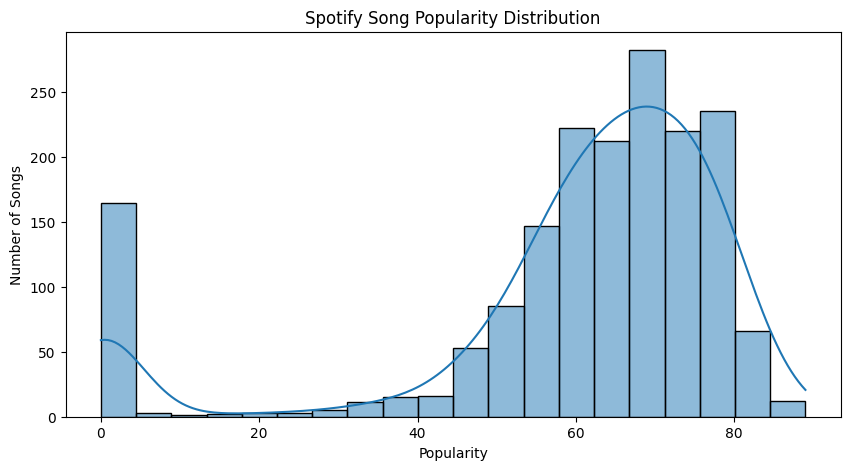

In [105]:
plt.figure(figsize=(10,5))

sns.histplot(
    df['popularity'],
    bins=20,
    kde=True
)

plt.title("Spotify Song Popularity Distribution")
plt.xlabel("Popularity")
plt.ylabel("Number of Songs")

plt.show()

**Popularity Classes Visualization**

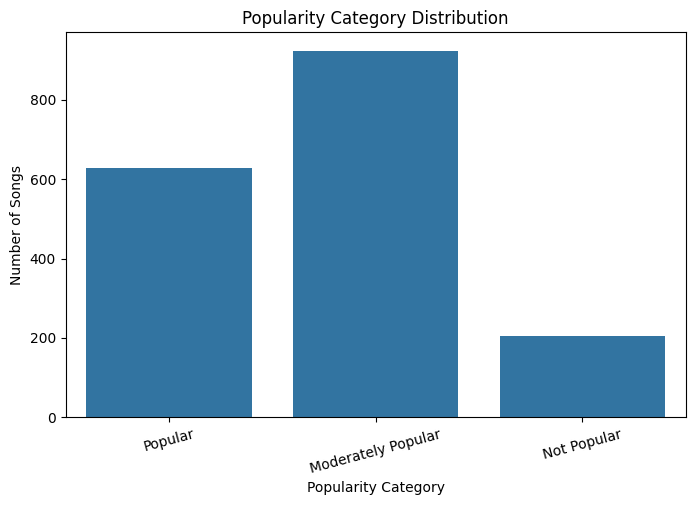

In [106]:
plt.figure(figsize=(8,5))

sns.countplot(
    data=df,
    x='popularity_category'
)

plt.title("Popularity Category Distribution")
plt.xlabel("Popularity Category")
plt.ylabel("Number of Songs")

plt.xticks(rotation=15)

plt.show()

**Feature Distribution**

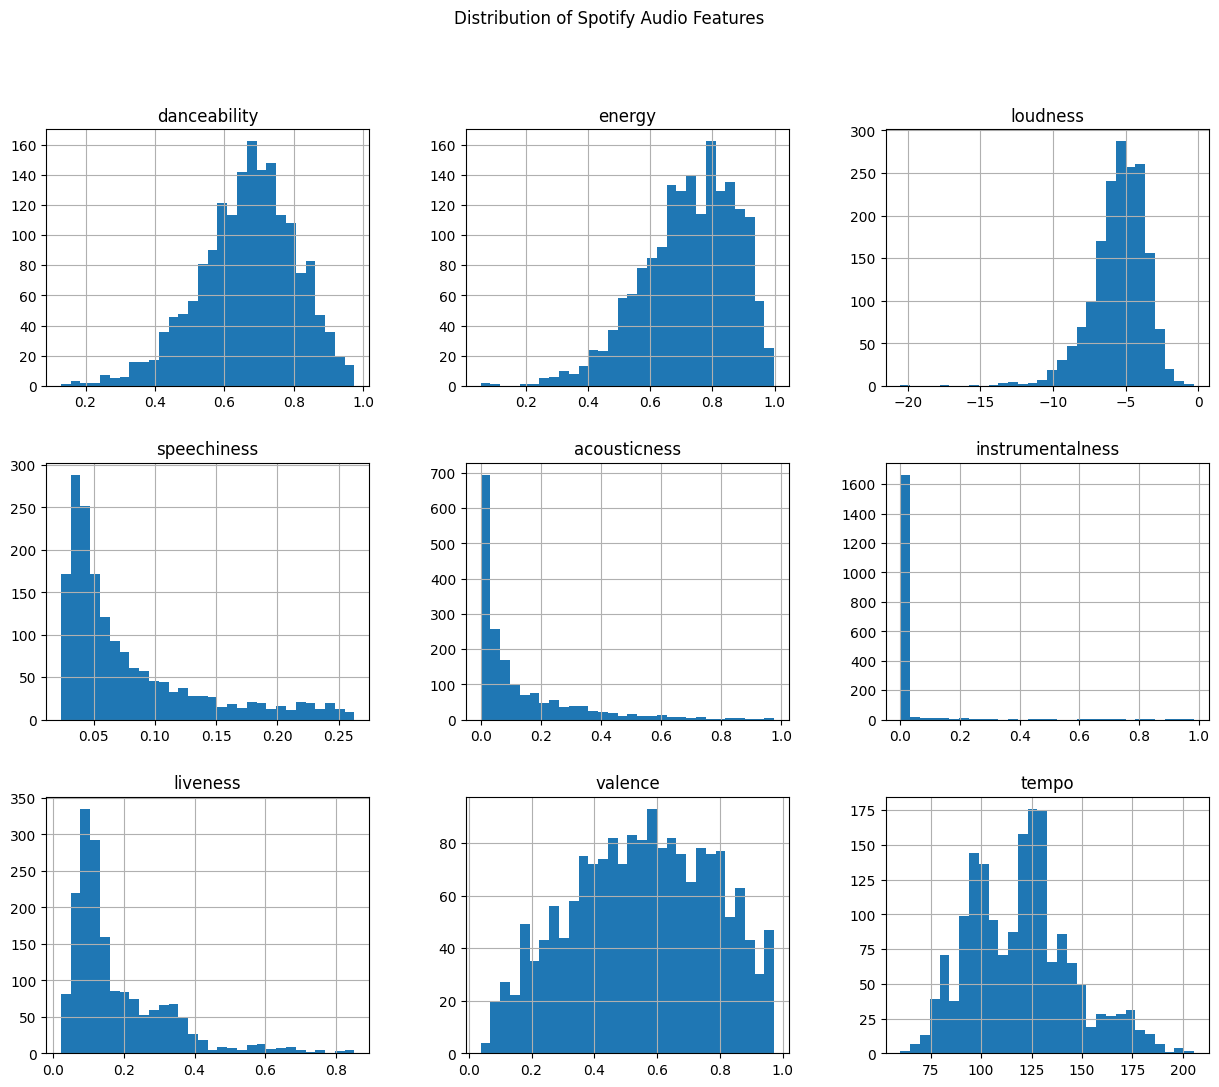

In [107]:
df[features].hist(
    figsize=(15,12),
    bins=30
)

plt.suptitle("Distribution of Spotify Audio Features")

plt.show()

**Data Preprocessing**

In [108]:
from sklearn.preprocessing import MinMaxScaler
from sklearn.preprocessing import StandardScaler
features = ["tempo", "danceability", "energy", "loudness"]

In [109]:
scaler = MinMaxScaler()
df_normalized = df.copy()
df_normalized[features] = scaler.fit_transform(
    df_normalized[features]
)


**Display the first five rows of the normalized numerical features**

In [110]:
print( df_normalized[features].head())

      tempo  danceability    energy  loudness
0  0.240699      0.735225  0.825230  0.744639
1  0.609456      0.360520  0.891961  0.770630
2  0.527925      0.472813  0.467217  0.568584
3  0.412041      0.498818  0.908908  0.812877
4  0.773866      0.573286  0.924796  0.776164


**Apply Standard Scaling to normalize numerical features**

In [111]:
scaler = StandardScaler()
df_standardized = df.copy()
df_standardized[features] = scaler.fit_transform(
    df_standardized[features]
)
print(df_standardized[features].head())

      tempo  danceability    energy  loudness
0 -0.970410      0.606905  0.717632  0.004363
1  1.139255     -1.668560  1.135416  0.282744
2  0.672812     -0.986638 -1.523814 -1.881324
3  0.009840     -0.828720  1.241520  0.735246
4  2.079845     -0.376498  1.340993  0.342020


**Data Splitting**

In [112]:
X = df[
    [
    "danceability",
    "acousticness",
    "valence",
    "tempo"
    ]
]
y = df["genre"]


In [113]:
X_train, X_test, y_train, y_test = train_test_split(
   X,
   y,
   test_size=0.20,
   random_state=42
)

print("Training data: ",X_train.shape)

print("Testing data: ", X_test.shape)


Training data:  (1405, 4)
Testing data:  (352, 4)


In [114]:
print(X_train.head())

      danceability  acousticness  valence    tempo
220          0.622       0.00107    0.537  142.017
808          0.949       0.00437    0.807  117.002
610          0.819       0.01760    0.386   96.998
1395         0.645       0.29400    0.862   82.324
1812         0.791       0.03700    0.592  123.994


**Feature selection**

**Correlation Heatmap**

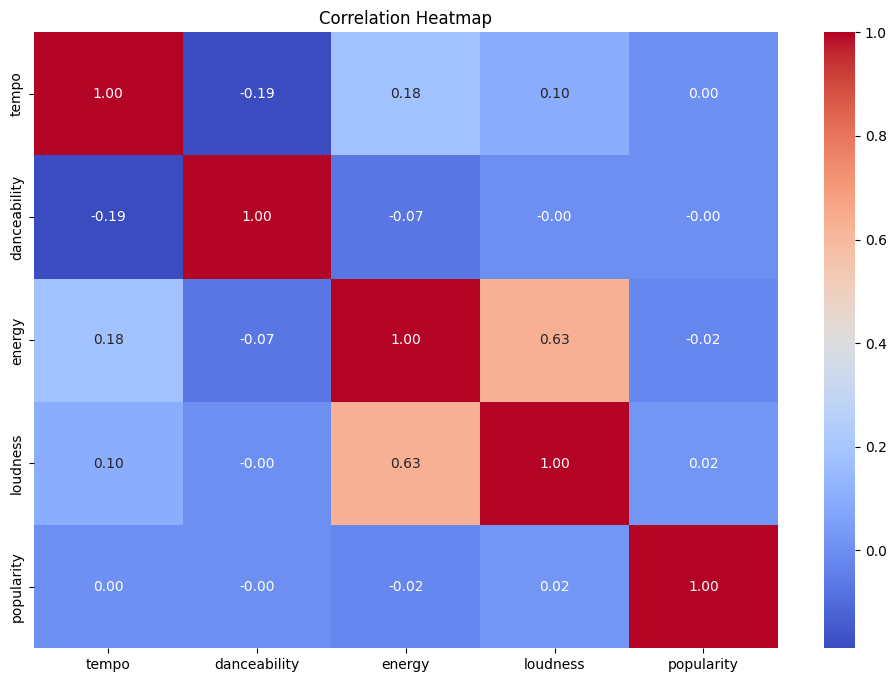

In [115]:
plt.figure(figsize=(12,8))

correlation = df[features + ['popularity']].corr()

sns.heatmap(
    correlation,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title("Correlation Heatmap")

plt.show()

**EDA**

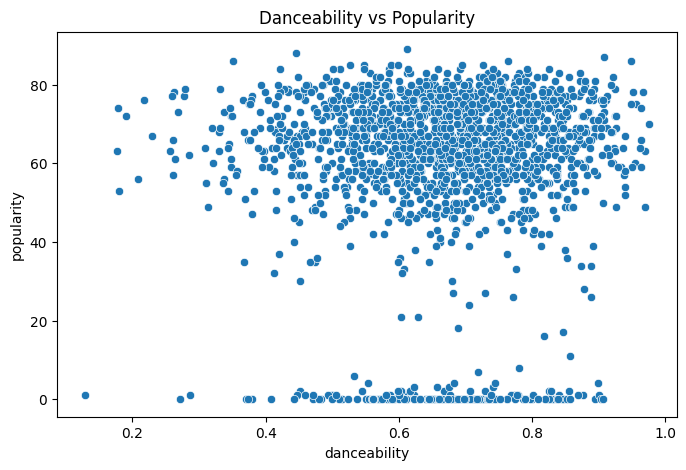

In [116]:
#Scatter Plots 1.Danceability vs Popularity
plt.figure(figsize=(8,5))

sns.scatterplot(
    data=df,
    x='danceability',
    y='popularity'
)

plt.title("Danceability vs Popularity")
plt.show()

**2.Energy vs Popularity**

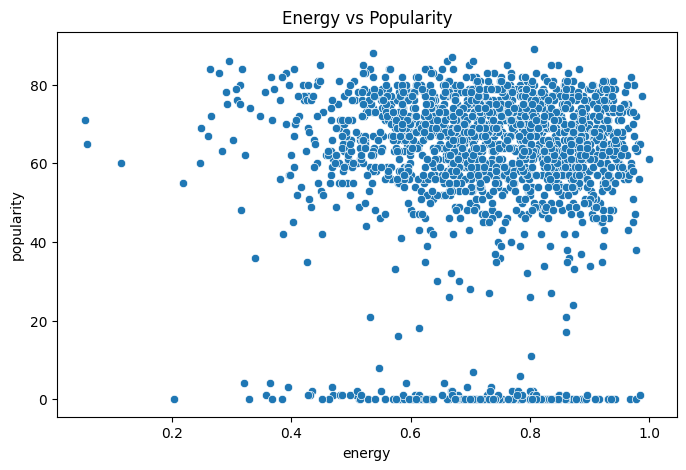

In [117]:
plt.figure(figsize=(8,5))

sns.scatterplot(
    data=df,
    x='energy',
    y='popularity'
)

plt.title("Energy vs Popularity")
plt.show()

**3.Valence vs Popularity**

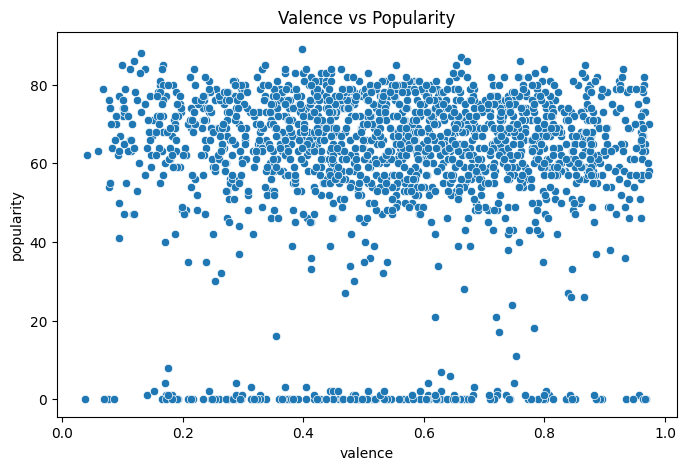

In [118]:
plt.figure(figsize=(8,5))

sns.scatterplot(
    data=df,
    x='valence',
    y='popularity'
)

plt.title("Valence vs Popularity")
plt.show()

**Preparation of X and Y and Checking**

In [119]:
X = df[features]

y = df['popularity_category']

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (1757, 4)
y shape: (1757,)


**Train-Test Split and Checking**

In [120]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)
print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (1405, 4)
Testing data: (352, 4)


**Feature Scaling Using Standard Scaler**

In [121]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Scaled training data:", X_train_scaled.shape)
print("Scaled testing data:", X_test_scaled.shape)

Scaled training data: (1405, 4)
Scaled testing data: (352, 4)


**Logistic Regression & Prediction**

In [122]:
logistic_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

logistic_model.fit(
    X_train_scaled,
    y_train
)
y_pred_logistic = logistic_model.predict(X_test_scaled)

print("===== Logistic Regression =====")
print("Model trained successfully!")
print("Training data shape:", X_train_scaled.shape)
print("Testing data shape:", X_test_scaled.shape)
print("Predictions generated:", len(y_pred_logistic))
print("First 10 predictions:")
print(y_pred_logistic[:10])

===== Logistic Regression =====
Model trained successfully!
Training data shape: (1405, 4)
Testing data shape: (352, 4)
Predictions generated: 352
First 10 predictions:
['Moderately Popular' 'Moderately Popular' 'Moderately Popular'
 'Moderately Popular' 'Moderately Popular' 'Moderately Popular'
 'Moderately Popular' 'Moderately Popular' 'Moderately Popular'
 'Moderately Popular']


**Model Training (SL)**

**Decision Tree & Prediction**

In [123]:
from sklearn.tree import DecisionTreeClassifier
decision_tree = DecisionTreeClassifier(
    random_state=42,
    max_depth=10
)
decision_tree.fit(X_train, y_train)
y_pred_tree = decision_tree.predict(X_test)
print("===== Decision Tree =====")
print("Model trained successfully!")
print("Training data shape:", X_train.shape)
print("Testing data shape:", X_test.shape)
print("Predictions generated:", len(y_pred_tree))
print("First 10 predictions:")
print(y_pred_tree[:10])

===== Decision Tree =====
Model trained successfully!
Training data shape: (1405, 4)
Testing data shape: (352, 4)
Predictions generated: 352
First 10 predictions:
['Popular' 'Moderately Popular' 'Popular' 'Moderately Popular'
 'Moderately Popular' 'Moderately Popular' 'Moderately Popular'
 'Moderately Popular' 'Popular' 'Moderately Popular']


**Random Forest**

In [124]:
from sklearn.ensemble import RandomForestClassifier

random_forest = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    n_jobs=-1
)

random_forest.fit(X_train, y_train)

y_pred_rf = random_forest.predict(X_test)

print("===== Random Forest =====")
print("Model trained successfully!")
print("Training data shape:", X_train.shape)
print("Testing data shape:", X_test.shape)
print("Predictions generated:", len(y_pred_rf))
print("First 10 predictions:")
print(y_pred_rf[:10])

===== Random Forest =====
Model trained successfully!
Training data shape: (1405, 4)
Testing data shape: (352, 4)
Predictions generated: 352
First 10 predictions:
['Popular' 'Popular' 'Popular' 'Popular' 'Moderately Popular' 'Popular'
 'Moderately Popular' 'Moderately Popular' 'Moderately Popular' 'Popular']


**Model Evaluation**

**Model Evaluation Function**

In [125]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

def evaluate_model(name, y_true, y_pred):

    accuracy = accuracy_score(y_true, y_pred)

    precision = precision_score(
        y_true,
        y_pred,
        average='weighted',
        zero_division=0
    )

    recall = recall_score(
        y_true,
        y_pred,
        average='weighted',
        zero_division=0
    )

    f1 = f1_score(
        y_true,
        y_pred,
        average='weighted',
        zero_division=0
    )

    print("=" * 50)
    print(name)
    print("=" * 50)

    print("Accuracy :", round(accuracy, 4))
    print("Precision:", round(precision, 4))
    print("Recall   :", round(recall, 4))
    print("F1 Score :", round(f1, 4))

    print("\nClassification Report:")
    print(classification_report(y_true, y_pred))

    return accuracy, precision, recall, f1

**Evaluate Logistic Regression**

In [126]:
logistic_results = evaluate_model(
    "Logistic Regression",
    y_test,
    y_pred_logistic
)

Logistic Regression
Accuracy : 0.5227
Precision: 0.4023
Recall   : 0.5227
F1 Score : 0.4028

Classification Report:
                    precision    recall  f1-score   support

Moderately Popular       0.54      0.95      0.69       185
       Not Popular       0.00      0.00      0.00        41
           Popular       0.33      0.07      0.12       126

          accuracy                           0.52       352
         macro avg       0.29      0.34      0.27       352
      weighted avg       0.40      0.52      0.40       352



**Evaluate Decision Tree**

In [127]:
logistic_results = evaluate_model(
    "Logistic Regression",
    y_test,
    y_pred_logistic
)

Logistic Regression
Accuracy : 0.5227
Precision: 0.4023
Recall   : 0.5227
F1 Score : 0.4028

Classification Report:
                    precision    recall  f1-score   support

Moderately Popular       0.54      0.95      0.69       185
       Not Popular       0.00      0.00      0.00        41
           Popular       0.33      0.07      0.12       126

          accuracy                           0.52       352
         macro avg       0.29      0.34      0.27       352
      weighted avg       0.40      0.52      0.40       352



**Evaluate Random Forest**

In [128]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

rf_results = evaluate_model(
    "Random Forest",
    y_test,
    y_pred_rf
)

Random Forest
Accuracy : 0.4631
Precision: 0.402
Recall   : 0.4631
F1 Score : 0.4271

Classification Report:
                    precision    recall  f1-score   support

Moderately Popular       0.53      0.68      0.59       185
       Not Popular       0.00      0.00      0.00        41
           Popular       0.35      0.30      0.32       126

          accuracy                           0.46       352
         macro avg       0.29      0.33      0.31       352
      weighted avg       0.40      0.46      0.43       352



**Model Compare**

In [129]:
# Model Comparison
import pandas as pd

results = pd.DataFrame({
    'Model': [
        'Logistic Regression',
        'Random Forest'
    ],
    'Accuracy': [
        logistic_results[0],
        rf_results[0]
    ],
    'Precision': [
        logistic_results[1],
        rf_results[1]
    ],
    'Recall': [
        logistic_results[2],
        rf_results[2]
    ],
    'F1 Score': [
        logistic_results[3],
        rf_results[3]
    ]
})

print("===== Model Performance Comparison =====")
display(results)

===== Model Performance Comparison =====


,Model,Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,0.522727,0.402316,0.522727,0.402796
1,Random Forest,0.463068,0.401990,0.463068,0.427120


**Model Comparison Graph**

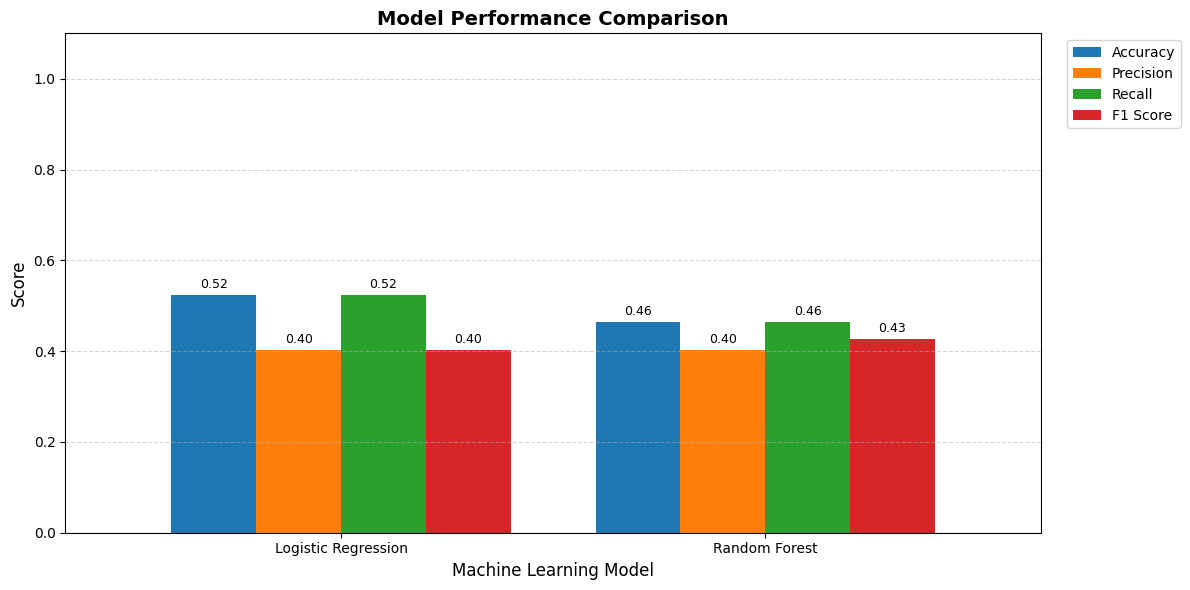

In [130]:
import matplotlib.pyplot as plt

# Plot grouped bar chart
ax = results.set_index("Model").plot(kind="bar", figsize=(12, 6), width=0.8)

plt.title("Model Performance Comparison", fontsize=14, fontweight="bold")
plt.ylabel("Score", fontsize=12)
plt.xlabel("Machine Learning Model", fontsize=12)
plt.ylim(0, 1.1)  # Raised slightly to give room for labels above bars
plt.xticks(rotation=0)
plt.grid(axis="y", linestyle="--", alpha=0.5)

# Add exact score values on top of each bar
for container in ax.containers:
    ax.bar_label(container, fmt="%.2f", padding=3, fontsize=9)

plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

**Model Evaluation**

**Confusion Matrix**

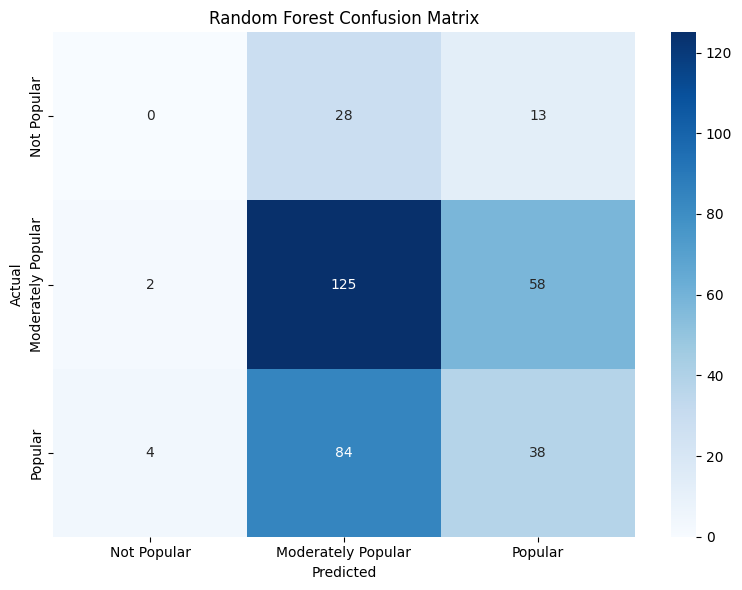

In [131]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

cm = confusion_matrix(
    y_test,
    y_pred_rf,
    labels=[
        'Not Popular',
        'Moderately Popular',
        'Popular'
    ]
)

plt.figure(figsize=(8, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=[
        'Not Popular',
        'Moderately Popular',
        'Popular'
    ],
    yticklabels=[
        'Not Popular',
        'Moderately Popular',
        'Popular'
    ]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Random Forest Confusion Matrix")

plt.tight_layout()
plt.show()

**Model Interpretation / Feature Analysis**

**Feature Independence**

**1. Calculate Feature Importance**

In [132]:
import pandas as pd

importance = pd.DataFrame({
    'Feature': features,
    'Importance': random_forest.feature_importances_
})

importance = importance.sort_values(
    by='Importance',
    ascending=False
)

print("===== Feature Importance =====")
display(importance)

===== Feature Importance =====


,Feature,Importance
2,energy,0.259361
3,loudness,0.253460
0,tempo,0.252389
1,danceability,0.234790


**2. Feature Importance Graph**

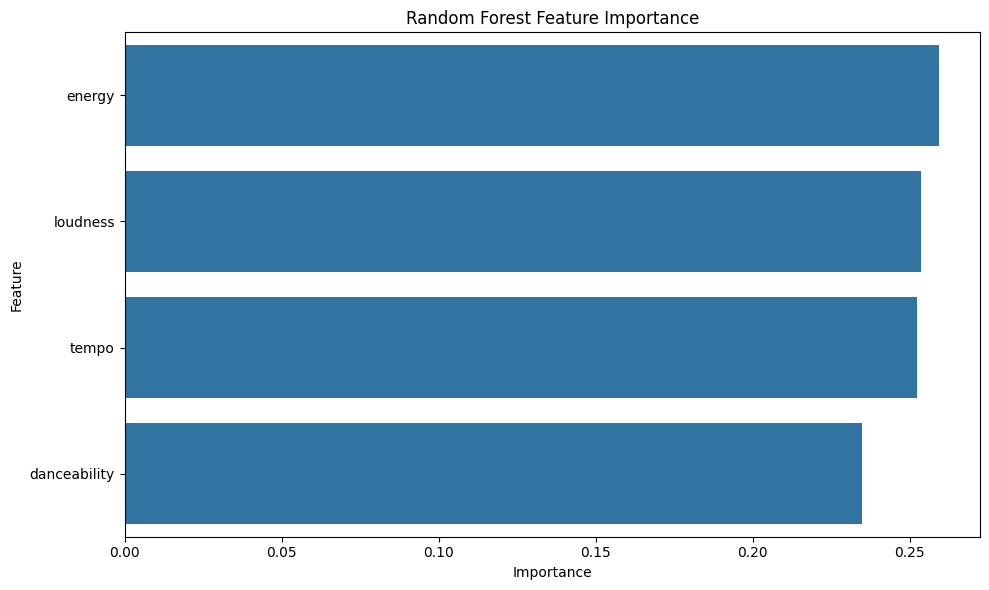

In [133]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 6))

sns.barplot(
    data=importance,
    x='Importance',
    y='Feature'
)

plt.title("Random Forest Feature Importance")
plt.xlabel("Importance")
plt.ylabel("Feature")

plt.tight_layout()
plt.show()

**Create New Song**

In [134]:
new_song = pd.DataFrame({
    'danceability': [0.80],
    'energy': [0.75],
    'loudness': [-5.0],
    'speechiness': [0.05],
    'acousticness': [0.10],
    'instrumentalness': [0.01],
    'liveness': [0.10],
    'valence': [0.80],
    'tempo': [120]
})

print("===== New Song Features =====")
display(new_song)

===== New Song Features =====


,danceability,energy,loudness,speechiness,acousticness,instrumentalness,liveness,valence,tempo
0,0.8,0.75,-5.0,0.05,0.1,0.01,0.1,0.8,120


**Check the training feature names**

In [135]:
# Display the features used during model training
print("Training Features:")
print(random_forest.feature_names_in_)

Training Features:
['tempo' 'danceability' 'energy' 'loudness']


**Check your new_song columns**

In [136]:
# Display the features in the new song dataset
print("New Song Features:")
print(new_song.columns.tolist())

New Song Features:
['danceability', 'energy', 'loudness', 'speechiness', 'acousticness', 'instrumentalness', 'liveness', 'valence', 'tempo']


**Correct the new_song columns**

In [137]:
# Match new song columns with training features
new_song = new_song[random_forest.feature_names_in_]

**Predict Popularity**

In [138]:
# Predict the popularity category
prediction = random_forest.predict(new_song)

# Display prediction result
print("===== Prediction Result =====")
print("Predicted Popularity Category:", prediction[0])

===== Prediction Result =====
Predicted Popularity Category: Moderately Popular


**Prediction Probability**

In [139]:
probability = random_forest.predict_proba(new_song)

print("===== Prediction Probabilities =====")

for category, prob in zip(
    random_forest.classes_,
    probability[0]
):
    print(f"{category}: {prob * 100:.2f}%")

===== Prediction Probabilities =====
Moderately Popular: 46.00%
Not Popular: 14.50%
Popular: 39.50%
